# Optimización de Portafolios — Markowitz + ML/DL

## Parte 1: Modelo Clásico de Markowitz

**Jacqueline Espinosa** — Lic. en Actuaría, FCFM UANL
Octubre 2026

---

Este proyecto implementa la optimización de portafolios de Markowitz en Python, y más adelante le agrega una capa de Machine Learning y Deep Learning para mejorar las predicciones de rendimiento.

**Plan del proyecto:**

| Parte | Qué hace | |
|-------|----------|-|
| 1 — Markowitz | Optimización clásica media-varianza | (este notebook) |
| 2 — ML | XGBoost / Random Forest para predecir rendimientos | pendiente |
| 3 — DL | LSTM para series de tiempo | pendiente |
| 4 — Backtesting | Comparar Markowitz puro vs ML vs DL | pendiente |


---
## Contexto teórico

Markowitz (1952) propone que al armar un portafolio no solo importa el rendimiento de cada activo, sino cómo se mueven entre sí. Si combinas activos que no están muy correlacionados, el riesgo total del portafolio baja sin que pierdas tanto rendimiento. Esa es básicamente la idea de la diversificación.

Las fórmulas principales que se usan:

**Rendimiento diario:**

$$r_t = \frac{P_t}{P_{t-1}} - 1$$

**Para anualizar** (asumiendo 252 días hábiles):
- Rendimiento: $E[R] = \bar{r}_{diario} \times 252$
- Volatilidad: $\sigma = \sigma_{diario} \times \sqrt{252}$

La volatilidad se multiplica por raíz de 252 y no por 252 directo porque la varianza es la que escala linealmente, y la desviación estándar es la raíz de la varianza.

**Rendimiento y riesgo del portafolio:**

$$R_p = \mathbf{w}^T \mathbf{R} \qquad \sigma_p^2 = \mathbf{w}^T \Sigma \mathbf{w}$$

donde $\mathbf{w}$ son los pesos y $\Sigma$ es la matriz de covarianzas.

**Sharpe Ratio:**

$$S = \frac{R_p - R_f}{\sigma_p}$$

Mide cuánto rendimiento extra obtienes por cada unidad de riesgo. $R_f$ es la tasa libre de riesgo (usamos 5%, aprox. T-Bills de EE.UU.).


---
## 1. Librerías

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf
from scipy.optimize import minimize
import warnings
warnings.filterwarnings('ignore')

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (12, 7)
plt.rcParams['font.size'] = 12


## 2. Datos

Escogí 10 acciones del S&P 500 tratando de que fueran de sectores distintos para que la diversificación tenga sentido. Si pongo puras tech, la correlación va a ser alta y el modelo no va a poder reducir el riesgo tanto.

Uso SPY (el ETF del S&P 500) como benchmark.


In [3]:
TICKERS = [
    'AAPL',   # Apple — Tech
    'MSFT',   # Microsoft — Tech
    'JPM',    # JPMorgan — Financiero
    'JNJ',    # Johnson & Johnson — Salud
    'XOM',    # ExxonMobil — Energia
    'KO',     # Coca-Cola — Consumo basico
    'AMZN',   # Amazon — Consumo discrecional
    'NVDA',   # Nvidia — Semiconductores
    'CAT',    # Caterpillar — Industrial
    'PG',     # Procter & Gamble — Consumo basico
]

BENCHMARK = 'SPY'
START = '2020-01-01'
END = '2024-12-31'
RISK_FREE_RATE = 0.05    # ~5% T-Bills EE.UU.
TRADING_DAYS = 252


Descargo los precios de cierre ajustados con `yfinance`. El precio ajustado ya trae incorporados dividendos y splits, entonces los rendimientos que calcule reflejan lo que realmente ganó el inversionista.

In [5]:
all_tickers = TICKERS + [BENCHMARK]
data = yf.download(all_tickers, start=START, end=END, auto_adjust=True)

# Extraer precios de cierre
if isinstance(data.columns, pd.MultiIndex):
    prices = data['Close'][all_tickers]
else:
    prices = data[all_tickers]

# Si alguna accion fallo, quitarla en vez de tirar todo
failed = prices.columns[prices.isna().all()]
if len(failed) > 0:
    print(f"No se pudieron descargar: {list(failed)}")
    print("Vuelve a correr esta celda. Si sigue fallando, reinicia el kernel.")

prices = prices.dropna()

print(f"Periodo: {prices.index[0].date()} a {prices.index[-1].date()}")
print(f"Dias de trading: {len(prices)}")

portfolio_prices = prices[TICKERS]
benchmark_prices = prices[BENCHMARK]

prices.head()


[*********************100%***********************]  11 of 11 completed

Periodo: 2020-01-02 a 2024-12-30
Dias de trading: 1257


Ticker,AAPL,MSFT,JPM,JNJ,XOM,KO,AMZN,NVDA,CAT,PG,SPY
Date,,,,,,,,,,,
2020-01-02,72.271553,151.544281,117.313934,121.338531,52.606392,44.873493,94.900497,5.957137,131.754501,103.275620,295.391724
2020-01-03,71.568939,149.657257,115.765823,119.933701,52.183475,44.628693,93.748497,5.861787,129.925201,102.581039,293.155090
2020-01-06,72.139191,150.044144,115.673767,119.784042,52.584133,44.612370,95.143997,5.886371,129.837708,102.723282,294.273407
2020-01-07,71.799919,148.676025,113.707237,120.515564,52.153793,44.269634,95.343002,5.957635,128.122147,102.087280,293.445984
2020-01-08,72.954926,151.044220,114.594254,120.498932,51.367298,44.351231,94.598503,5.968810,129.259979,102.522446,295.009857


## 3. Rendimientos diarios

Calculo el rendimiento diario como el cambio porcentual del precio. Toda la teoría de Markowitz trabaja con rendimientos, no con precios directamente, porque los rendimientos son estacionarios (oscilan alrededor de un promedio).

In [6]:
daily_returns = portfolio_prices.pct_change().dropna()
benchmark_returns = benchmark_prices.pct_change().dropna()

print(f"Observaciones: {len(daily_returns)}")
daily_returns.head()


Observaciones: 1256


Ticker,AAPL,MSFT,JPM,JNJ,XOM,KO,AMZN,NVDA,CAT,PG
Date,,,,,,,,,,
2020-01-03,-0.009722,-0.012452,-0.013196,-0.011578,-0.008039,-0.005455,-0.012139,-0.016006,-0.013884,-0.006725
2020-01-06,0.007968,0.002585,-0.000795,-0.001248,0.007678,-0.000366,0.014886,0.004194,-0.000673,0.001387
2020-01-07,-0.004703,-0.009118,-0.017001,0.006107,-0.008184,-0.007683,0.002092,0.012107,-0.013213,-0.006191
2020-01-08,0.016086,0.015929,0.007801,-0.000138,-0.015080,0.001843,-0.007809,0.001876,0.008881,0.004263
2020-01-09,0.021241,0.012493,0.003651,0.002966,0.007655,0.018216,0.004799,0.010982,-0.002506,0.010938


### Estadísticas anualizadas

Ahora calculo el rendimiento esperado y la volatilidad de cada acción, ya anualizados.

In [7]:
expected_returns = daily_returns.mean() * TRADING_DAYS
volatility = daily_returns.std() * np.sqrt(TRADING_DAYS)

summary = pd.DataFrame({
    'Rendimiento (%)': (expected_returns * 100).round(2),
    'Volatilidad (%)': (volatility * 100).round(2),
    'Sharpe': ((expected_returns - RISK_FREE_RATE) / volatility).round(3)
}).sort_values('Sharpe', ascending=False)

summary


,Rendimiento (%),Volatilidad (%),Sharpe
Ticker,,,
NVDA,77.38,53.89,1.343
AAPL,29.95,31.69,0.787
MSFT,25.07,30.51,0.658
CAT,25.16,32.50,0.620
AMZN,23.46,35.98,0.513
JPM,18.78,32.54,0.423
XOM,18.80,34.39,0.401
PG,10.75,20.93,0.274
KO,7.70,20.81,0.130


El Sharpe negativo (si lo hay) significa que la acción ni siquiera le ganó a la tasa libre de riesgo — habrías ganado más comprando T-Bills sin ningún riesgo.

## 4. Correlaciones y covarianzas

La matriz de covarianzas $\Sigma$ es lo que hace funcionar a Markowitz. Cada elemento fuera de la diagonal mide cuánto se mueven juntos dos activos. La correlación es la versión normalizada (entre -1 y +1).

Para la diversificación lo que conviene son correlaciones bajas (<0.5). Si dos acciones tienen correlación de 0.9, meter las dos al portafolio casi no reduce el riesgo.

In [8]:
cov_matrix = daily_returns.cov() * TRADING_DAYS
corr_matrix = daily_returns.corr()

corr_matrix.round(2)


Ticker,AAPL,MSFT,JPM,JNJ,XOM,KO,AMZN,NVDA,CAT,PG
Ticker,,,,,,,,,,
AAPL,1.00,0.75,0.41,0.37,0.28,0.44,0.59,0.61,0.35,0.43
MSFT,0.75,1.00,0.42,0.38,0.24,0.43,0.68,0.68,0.35,0.46
JPM,0.41,0.42,1.00,0.41,0.57,0.53,0.27,0.33,0.63,0.37
JNJ,0.37,0.38,0.41,1.00,0.30,0.59,0.18,0.15,0.35,0.62
XOM,0.28,0.24,0.57,0.30,1.00,0.43,0.13,0.18,0.59,0.23
KO,0.44,0.43,0.53,0.59,0.43,1.00,0.22,0.22,0.42,0.65
AMZN,0.59,0.68,0.27,0.18,0.13,0.22,1.00,0.58,0.25,0.23
NVDA,0.61,0.68,0.33,0.15,0.18,0.22,0.58,1.00,0.33,0.23
CAT,0.35,0.35,0.63,0.35,0.59,0.42,0.25,0.33,1.00,0.28


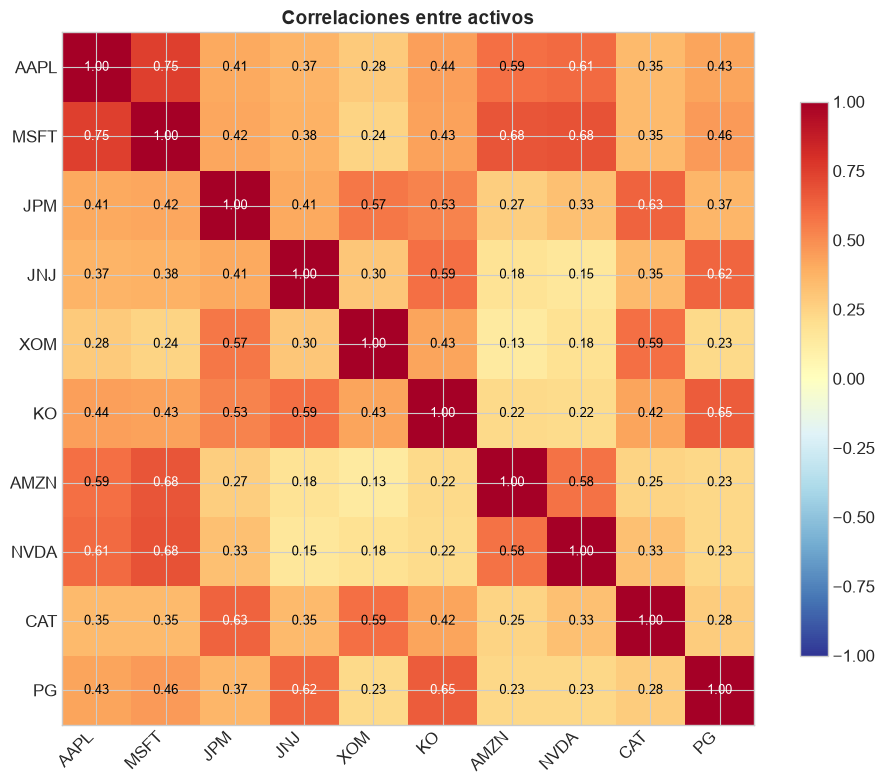

In [9]:
# Mapa de calor
fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(corr_matrix.values, cmap='RdYlBu_r', vmin=-1, vmax=1)

ax.set_xticks(range(len(TICKERS)))
ax.set_yticks(range(len(TICKERS)))
ax.set_xticklabels(TICKERS, rotation=45, ha='right')
ax.set_yticklabels(TICKERS)

for i in range(len(TICKERS)):
    for j in range(len(TICKERS)):
        color = 'white' if abs(corr_matrix.iloc[i, j]) > 0.6 else 'black'
        ax.text(j, i, f'{corr_matrix.iloc[i, j]:.2f}',
                ha='center', va='center', fontsize=9, color=color)

plt.colorbar(im, ax=ax, shrink=0.8)
ax.set_title('Correlaciones entre activos', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()


Se nota cómo las de tech (AAPL, MSFT, AMZN, NVDA) tienen correlación alta entre sí — se mueven juntas. Las defensivas (JNJ, KO, PG) forman otro bloque. La diversificación real viene de combinar activos de bloques distintos.

## 5. Funciones de optimización

`scipy.optimize.minimize` hace lo mismo que Solver de Excel. Le paso una función objetivo, restricciones y límites, y encuentra los pesos que minimizan esa función.

Para el portafolio de máximo Sharpe, como `minimize` solo minimiza, le paso el Sharpe con signo negativo: minimizar $-S$ es lo mismo que maximizar $S$.

In [10]:
def portfolio_performance(weights, exp_ret, cov_mat):
    """Rendimiento, volatilidad y Sharpe de un portafolio."""
    ret = np.dot(weights, exp_ret)
    vol = np.sqrt(np.dot(weights.T, np.dot(cov_mat, weights)))
    sharpe = (ret - RISK_FREE_RATE) / vol
    return ret, vol, sharpe

def neg_sharpe(w, exp_ret, cov_mat):
    """Sharpe negativo (minimizar esto = maximizar Sharpe)."""
    return -(np.dot(w, exp_ret) - RISK_FREE_RATE) / np.sqrt(np.dot(w.T, np.dot(cov_mat, w)))

def port_vol(w, exp_ret, cov_mat):
    """Volatilidad del portafolio: sqrt(w'Σw)."""
    return np.sqrt(np.dot(w.T, np.dot(cov_mat, w)))

n_assets = len(TICKERS)
x0 = np.array([1/n_assets] * n_assets)     # pesos iniciales: 1/n
cons = {'type': 'eq', 'fun': lambda w: np.sum(w) - 1}  # suman 1
bnds = tuple((0, 1) for _ in range(n_assets))           # sin short-selling


## 6. Portafolio de Mínima Varianza

Minimiza $\sigma_p = \sqrt{w^T \Sigma w}$ sujeto a que los pesos sumen 1 y estén entre 0 y 1. Es el punto más a la izquierda de la frontera eficiente, el de menor riesgo posible.

In [11]:
res_mv = minimize(port_vol, x0,
                  args=(expected_returns.values, cov_matrix.values),
                  method='SLSQP', bounds=bnds, constraints=cons)

w_mv = res_mv.x
ret_mv, vol_mv, sh_mv = portfolio_performance(w_mv, expected_returns.values, cov_matrix.values)

print(f"Rendimiento: {ret_mv*100:.2f}%")
print(f"Volatilidad: {vol_mv*100:.2f}%")
print(f"Sharpe:      {sh_mv:.4f}")
print(f"\nPesos:")
for t, w in zip(TICKERS, w_mv):
    if w > 0.001:
        print(f"  {t:6s}: {w*100:.2f}%")


Rendimiento: 10.05%
Volatilidad: 16.86%
Sharpe:      0.2999

Pesos:
  JNJ   : 38.40%
  XOM   : 6.62%
  KO    : 18.86%
  AMZN  : 11.40%
  CAT   : 2.49%
  PG    : 22.23%


Sale bastante peso en las acciones defensivas (PG, JNJ, KO) que son las de menor volatilidad. Tiene sentido: si quieres minimizar riesgo, te cargas a lo más estable. NVDA ni aparece a pesar de su rendimiento alto, porque su volatilidad es demasiada.

## 7. Portafolio de Máximo Sharpe (Tangencia)

Maximiza $S = \frac{R_p - R_f}{\sigma_p}$. Este portafolio da la mejor relación rendimiento/riesgo posible. En el CAPM se le llama portafolio de mercado, y es donde la CML toca la frontera eficiente.

In [12]:
res_ms = minimize(neg_sharpe, x0,
                  args=(expected_returns.values, cov_matrix.values),
                  method='SLSQP', bounds=bnds, constraints=cons)

w_ms = res_ms.x
ret_ms, vol_ms, sh_ms = portfolio_performance(w_ms, expected_returns.values, cov_matrix.values)

print(f"Rendimiento: {ret_ms*100:.2f}%")
print(f"Volatilidad: {vol_ms*100:.2f}%")
print(f"Sharpe:      {sh_ms:.4f}")
print(f"\nPesos:")
for t, w in zip(TICKERS, w_ms):
    if w > 0.001:
        print(f"  {t:6s}: {w*100:.2f}%")


Rendimiento: 64.91%
Volatilidad: 44.10%
Sharpe:      1.3583

Pesos:
  XOM   : 7.29%
  NVDA  : 76.99%
  CAT   : 15.71%


Aquí sí pesa más el rendimiento. Se concentra en las acciones con mejor Sharpe individual. Es más agresivo que el de mínima varianza pero más eficiente por unidad de riesgo.

Una limitación importante: estos pesos se calcularon con datos históricos. No hay garantía de que el futuro se comporte igual. Eso es justo lo que van a intentar resolver las Partes 2 y 3 con ML/DL — predecir rendimientos en vez de asumir que el promedio histórico se repite.

## 8. Frontera Eficiente

Para cada nivel de rendimiento objetivo, encuentro los pesos que minimizan la volatilidad. La curva que resulta es la frontera eficiente — todos los portafolios por debajo son subóptimos.

In [13]:
targets = np.linspace(expected_returns.min(), expected_returns.max(), 80)
front_vol, front_ret = [], []

for t in targets:
    c = [cons, {'type': 'eq', 'fun': lambda w, tgt=t: np.dot(w, expected_returns.values) - tgt}]
    r = minimize(port_vol, x0, args=(expected_returns.values, cov_matrix.values),
                 method='SLSQP', bounds=bnds, constraints=c)
    if r.success:
        front_vol.append(port_vol(r.x, expected_returns.values, cov_matrix.values))
        front_ret.append(t)

print(f"Portafolios en la frontera: {len(front_ret)}")


Portafolios en la frontera: 80


## 9. Monte Carlo

Simulo 50,000 portafolios con pesos aleatorios (distribución Dirichlet, que genera vectores positivos que suman 1) para visualizar el espacio de posibilidades. La mayoría caen lejos de la frontera — son ineficientes.

In [14]:
N_SIM = 50_000
np.random.seed(42)
sim_w = np.random.dirichlet(np.ones(n_assets), N_SIM)
sim_ret = sim_w @ expected_returns.values
sim_vol = np.array([np.sqrt(w @ cov_matrix.values @ w) for w in sim_w])
sim_sh = (sim_ret - RISK_FREE_RATE) / sim_vol

print(f"Portafolios simulados: {N_SIM:,}")


Portafolios simulados: 50,000


## 10. Capital Market Line

La CML es la recta desde $R_f$ tangente a la frontera eficiente:

$$R_{CML} = R_f + S^* \cdot \sigma$$

donde $S^*$ es el Sharpe del portafolio de tangencia. Todo inversionista racional debería estar sobre esta línea, combinando el portafolio de tangencia con el activo libre de riesgo.

In [15]:
cml_x = np.linspace(0, max(sim_vol) * 0.8, 100)
cml_y = RISK_FREE_RATE + sh_ms * cml_x


## 11. Gráfica principal

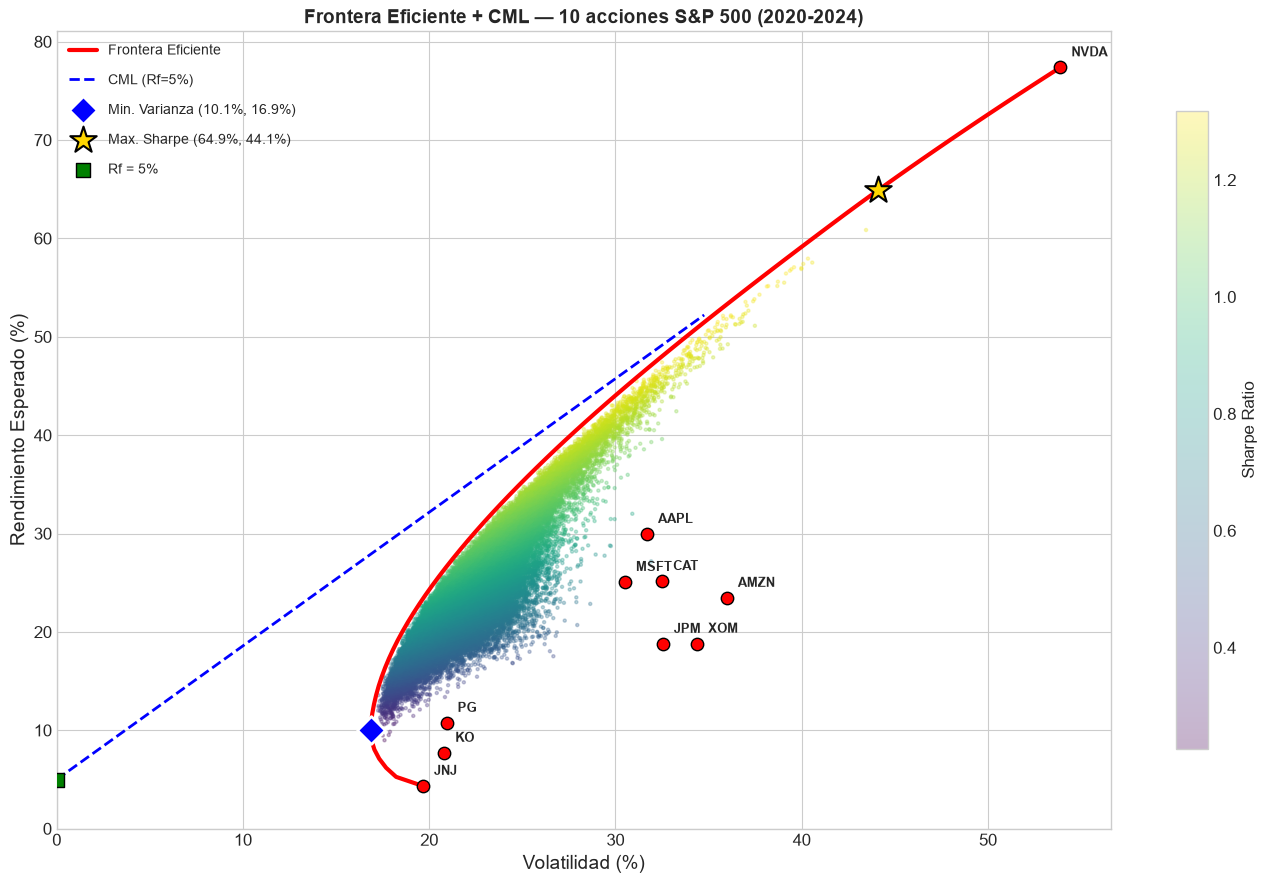

In [19]:
fig, ax = plt.subplots(figsize=(14, 9))

# Monte Carlo
sc = ax.scatter(sim_vol*100, sim_ret*100, c=sim_sh, cmap='viridis', alpha=0.3, s=5)
plt.colorbar(sc, ax=ax, label='Sharpe Ratio', shrink=0.8)

# Frontera eficiente
ax.plot(np.array(front_vol)*100, np.array(front_ret)*100,
        'r-', lw=3, label='Frontera Eficiente')

# CML
ax.plot(cml_x*100, cml_y*100, 'b--', lw=2,
        label=f'CML (Rf={RISK_FREE_RATE*100:.0f}%)')

# Portafolios optimos
ax.scatter(vol_mv*100, ret_mv*100, marker='D', s=200, c='blue',
           edgecolors='white', lw=2, zorder=5,
           label=f'Min. Varianza ({ret_mv*100:.1f}%, {vol_mv*100:.1f}%)')
ax.scatter(vol_ms*100, ret_ms*100, marker='*', s=400, c='gold',
           edgecolors='black', lw=1.5, zorder=5,
           label=f'Max. Sharpe ({ret_ms*100:.1f}%, {vol_ms*100:.1f}%)')

# Activos individuales
for i, tk in enumerate(TICKERS):
    ax.scatter(volatility[tk]*100, expected_returns[tk]*100,
               marker='o', s=80, c='red', edgecolors='black', zorder=4)
    ax.annotate(tk, (volatility[tk]*100, expected_returns[tk]*100),
                fontsize=9, fontweight='bold', xytext=(8, 8), textcoords='offset points')

ax.scatter(0, RISK_FREE_RATE*100, marker='s', s=100, c='green',
           edgecolors='black', zorder=5, label=f'Rf = {RISK_FREE_RATE*100:.0f}%')

ax.set_xlabel('Volatilidad (%)', fontsize=14)
ax.set_ylabel('Rendimiento Esperado (%)', fontsize=14)
ax.set_title('Frontera Eficiente + CML — 10 acciones S&P 500 (2020-2024)',
             fontsize=14, fontweight='bold')
ax.legend(loc='upper left', fontsize=10, framealpha=0.9, labelspacing=1.2)
ax.set_xlim(left=0)
ax.set_ylim(bottom=0)
plt.tight_layout()
plt.show()


Todas las acciones individuales (puntos rojos) quedan por debajo de la frontera eficiente. Esto confirma que siempre conviene diversificar en vez de apostar a una sola acción.

## 12. Composición de portafolios

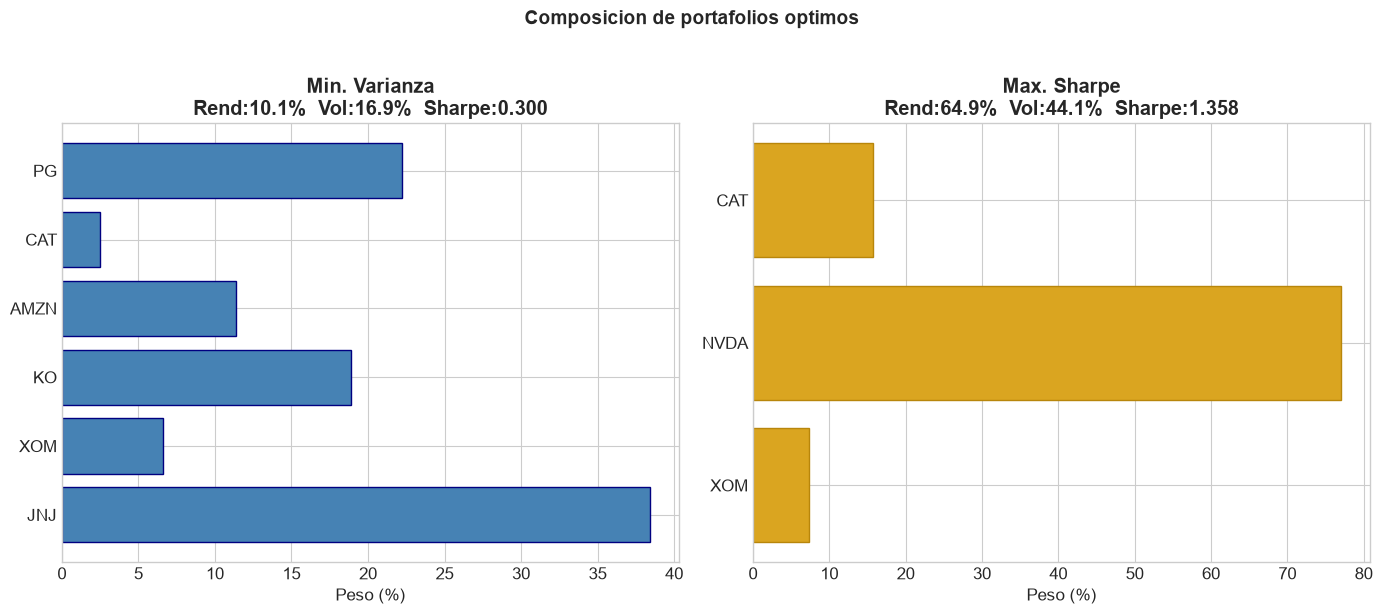

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

m1 = w_mv > 0.001
axes[0].barh(np.array(TICKERS)[m1], w_mv[m1]*100, color='steelblue', edgecolor='navy')
axes[0].set_xlabel('Peso (%)')
axes[0].set_title(f'Min. Varianza\nRend:{ret_mv*100:.1f}%  Vol:{vol_mv*100:.1f}%  Sharpe:{sh_mv:.3f}',
                  fontweight='bold')

m2 = w_ms > 0.001
axes[1].barh(np.array(TICKERS)[m2], w_ms[m2]*100, color='goldenrod', edgecolor='darkgoldenrod')
axes[1].set_xlabel('Peso (%)')
axes[1].set_title(f'Max. Sharpe\nRend:{ret_ms*100:.1f}%  Vol:{vol_ms*100:.1f}%  Sharpe:{sh_ms:.3f}',
                  fontweight='bold')

plt.suptitle('Composicion de portafolios optimos', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


## 13. Rendimiento acumulado

Backtest simple: si hubiera invertido $1 al inicio con estos pesos fijos, cuánto tendría al final. Incluyo un portafolio equal-weight (1/n en cada acción) como referencia.

Nota: este backtest es ingenuo porque usa los mismos datos para optimizar y evaluar. En la Parte 4 lo voy a hacer bien con datos fuera de muestra.

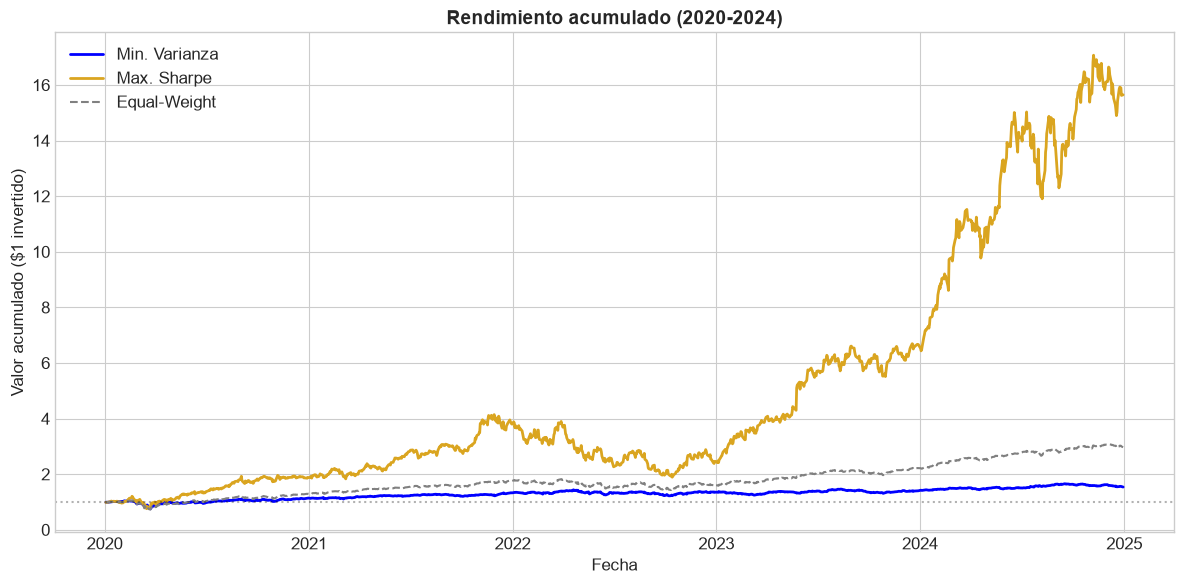

Rendimiento total:
  Min. Varianza: +53.8%
  Max. Sharpe:   +1464.7%
  Equal-Weight:  +197.0%


In [21]:
cum_mv = (1 + daily_returns @ w_mv).cumprod()
cum_ms = (1 + daily_returns @ w_ms).cumprod()
cum_ew = (1 + daily_returns.mean(axis=1)).cumprod()

fig, ax = plt.subplots(figsize=(12, 6))
ax.plot(cum_mv.index, cum_mv.values, 'b-', lw=2, label='Min. Varianza')
ax.plot(cum_ms.index, cum_ms.values, color='goldenrod', lw=2, label='Max. Sharpe')
ax.plot(cum_ew.index, cum_ew.values, 'gray', lw=1.5, ls='--', label='Equal-Weight')
ax.axhline(y=1, color='black', ls=':', alpha=0.3)

ax.set_xlabel('Fecha')
ax.set_ylabel('Valor acumulado ($1 invertido)')
ax.set_title('Rendimiento acumulado (2020-2024)', fontsize=14, fontweight='bold')
ax.legend()
plt.tight_layout()
plt.show()

print(f"Rendimiento total:")
print(f"  Min. Varianza: {(cum_mv.iloc[-1]-1)*100:+.1f}%")
print(f"  Max. Sharpe:   {(cum_ms.iloc[-1]-1)*100:+.1f}%")
print(f"  Equal-Weight:  {(cum_ew.iloc[-1]-1)*100:+.1f}%")


## 14. Resumen

In [22]:
resumen = pd.DataFrame({
    'Rendimiento (%)': [ret_mv*100, ret_ms*100, RISK_FREE_RATE*100],
    'Volatilidad (%)': [vol_mv*100, vol_ms*100, 0],
    'Sharpe': [sh_mv, sh_ms, 0]
}, index=['Min. Varianza', 'Max. Sharpe', 'Tasa Libre Riesgo'])

resumen.round(4)


,Rendimiento (%),Volatilidad (%),Sharpe
Min. Varianza,10.0546,16.8554,0.2999
Max. Sharpe,64.9070,44.1041,1.3583
Tasa Libre Riesgo,5.0000,0.0000,0.0000


### Conclusiones

La diversificación funciona: ninguna acción individual queda sobre la frontera eficiente. Combinar activos de sectores distintos reduce el riesgo del portafolio.

El portafolio de mínima varianza es mucho más estable pero da menos rendimiento. El de máximo Sharpe es más agresivo pero eficiente por unidad de riesgo.

La limitación principal de Markowitz es que asume que los rendimientos históricos van a seguir repitiéndose, y no necesariamente es así. En la Parte 2 voy a usar XGBoost y Random Forest para intentar predecir rendimientos futuros con features como indicadores técnicos y variables macroeconómicas, en vez de simplemente promediar el pasado.
